In [1]:
import os
import numpy as np
import tensorflow as tf
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import load_img, img_to_array

In [2]:
import kagglehub
from pathlib import Path

# Kaggle Vegetable Image Dataset (train split), downloaded once to the kagglehub cache.
# Only 4 classes and the first 500 images of each are used below.
VEG_DIR = Path(kagglehub.dataset_download("misrakahmed/vegetable-image-dataset")) / "Vegetable Images" / "train"
VEG_CLASSES = ["Broccoli", "Carrot", "Cucumber", "Tomato"]

C:\Users\jorda\Code\ml-notebooks\courses\deep-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  0%|          | 0.00/534M [00:00<?, ?B/s]

  0%|          | 1.00M/534M [00:00<03:37, 2.57MB/s]

  1%|          | 3.00M/534M [00:00<01:24, 6.62MB/s]

  1%|          | 5.00M/534M [00:00<00:57, 9.61MB/s]

  1%|▏         | 7.00M/534M [00:00<00:47, 11.5MB/s]

... (261 outputs left out)

 99%|█████████▉| 531M/534M [00:36<00:00, 16.2MB/s]

100%|█████████▉| 533M/534M [00:36<00:00, 16.0MB/s]

100%|██████████| 534M/534M [00:36<00:00, 15.3MB/s]

Extracting files...


In [3]:
path = str(VEG_DIR)
label_list = VEG_CLASSES

images = []
classes = []

for i, label in enumerate(label_list):
    full_path = os.path.join(path, label)
    for j, image in enumerate(sorted(os.listdir(full_path))[:500]):
        img_path = os.path.join(full_path, image)
        img = load_img(img_path)
        img = img_to_array(img)
        img = tf.image.rgb_to_grayscale(img)
        img = img / 255

        images.append(img)
        classes.append(i)

In [4]:
y = tf.keras.utils.to_categorical(classes, len(label_list))
images = np.asarray(images)

In [5]:
x_train, x_temp, y_train, y_temp = train_test_split(images, y, train_size=0.8, random_state=42)
x_test, x_val, y_test, y_val = train_test_split(x_temp, y_temp, train_size=0.5, random_state=42)

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(16, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same', input_shape=(224, 224, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(16, activation='relu', kernel_size=(3, 3), strides=(1, 1), padding='same'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(4, activation='softmax'),
])

C:\Users\jorda\Code\ml-notebooks\courses\deep-learning\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)
history = model.fit(
    x_train, 
    y_train,
    validation_data=(x_val, y_val),
    epochs=10,
    callbacks=early_stopping
)

Epoch 1/10


 1/50 ━━━━━━━━━━━━━━━━━━━━ 40s 830ms/step - accuracy: 0.2500 - loss: 1.3877

 3/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2708 - loss: 1.6167  

 5/50 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.2500 - loss: 1.5733

 7/50 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.2500 - loss: 1.5354

 9/50 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.2500 - loss: 1.5027

... (180 outputs left out)

45/50 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9611 - loss: 0.1102

47/50 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9608 - loss: 0.1104

49/50 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.9617 - loss: 0.1100

50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.9625 - loss: 0.1089 - val_accuracy: 0.8300 - val_loss: 0.4716


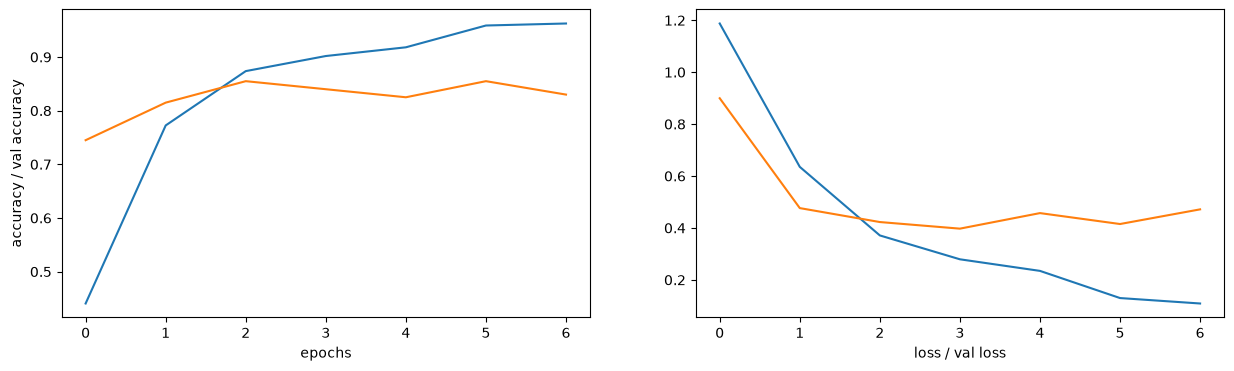

In [9]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel('epochs')
plt.ylabel('accuracy / val accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel('epochs')
plt.xlabel('loss / val loss')

plt.show()

In [10]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=2)
print('test loss: ', loss)
print('test accuracy: ', accuracy)

from sklearn.metrics import classification_report
y_preds_probs = model.predict(x_test)
y_pred = np.argmax(y_preds_probs, axis=1)
y_true = np.argmax(y_test, axis=1)

print(classification_report(y_true, y_pred, target_names=label_list))

7/7 - 0s - 15ms/step - accuracy: 0.8650 - loss: 0.3633


test loss:  0.3632673919200897
test accuracy:  0.8650000095367432
1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

6/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


              precision    recall  f1-score   support

    Broccoli       0.96      0.91      0.93        54
      Carrot       1.00      0.79      0.88        53
    Cucumber       0.75      0.93      0.83        41
      Tomato       0.79      0.85      0.81        52

    accuracy                           0.86       200
   macro avg       0.87      0.87      0.86       200
weighted avg       0.88      0.86      0.87       200

